# 16 · Deep learning with PyTorch I: tensors and a first network for EEG

**ROBT613 · Brain–Computer Interfaces** | PyTorch track, part 1 of 3 | Academic tutorial and independent exercises

## Goal
Represent EEG epochs and features as PyTorch tensors, build a fully connected network as an `nn.Module`, and pass real motor-imagery trials through it before any training.

**Data:** PhysioNet EEGBCI, subjects 1–5, imagery runs 4/8/12 (left versus right fist)

Run cells from top to bottom in a fresh CPU runtime. No previous notebook state is required. This lesson adapts the classic "Neural networks with PyTorch" MNIST tutorial to EEG: digit images become EEG trials and pixel intensities become log band-power features.

## Paradigm background and experimental design

### Why a neural network for a BCI?

Lessons 06 and 08 decoded motor imagery with hand-designed features and a linear classifier. A neural network learns a nonlinear mapping from inputs to class probabilities. In this first PyTorch lesson the inputs are still hand-designed features, log band power per channel, so the only new element is the classifier. Lesson 17 trains networks on these features and then on raw epochs; Lesson 18 learns compressed representations with an autoencoder.

### Motor imagery and sensorimotor rhythms

Motor imagery is the internal rehearsal of movement without overt execution. Imagining a hand movement typically reduces mu (8–13 Hz) and beta (13–30 Hz) power over the contralateral sensorimotor cortex, an event-related desynchronization (ERD). Band power over channels such as C3 and C4 is therefore a physiologically motivated input for a left-versus-right decoder. The spatial and spectral pattern varies across people, which is one motivation for learned models.

### Acquisition provenance and instructional protocol

PhysioNet EEGBCI: 64 scalp channels, 160 Hz, recorded with BCI2000. Runs 4, 8 and 12 contain cued imagery of the left or right fist (annotations T1 and T2), about 15 trials per participant per run, roughly half of each class. The original database also contains executed movements and other imagery tasks.

**Acquisition reference:** [PhysioNet EEG Motor Movement/Imagery Dataset](https://physionet.org/content/eegmmidb/1.0.0/).

| Experimental component | Role in this lesson |
|---|---|
| Participants 1–5 | Pooled to give the network more examples; each trial keeps its subject ID |
| Runs 4, 8, 12 | Three separate recording blocks with training, validation and test roles |
| 0.5–3.5 s after cue | Analysis window chosen for this lesson, not the full imagery period |
| 8–30 Hz band-pass | Keeps mu and beta rhythms; applied per run before epoching |

### Measurement model and interpretation

A scalp EEG sensor measures a potential difference in volts. The recorded signal mixes neural activity, physiological interference (eye, muscle) and environmental noise. A network trained on these signals can exploit any of these sources. Accuracy alone does not show that it learned motor imagery.

### Mathematical definitions for this lesson

A single artificial neuron computes $y=f\left(\sum_i w_ix_i+b\right)$ with weights $w_i$, bias $b$ and activation $f$. A fully connected layer applies many neurons at once: $\mathbf h=f(\mathbf xW^\top+\mathbf b)$, where $\mathbf x$ is a $1\times d$ feature row and $W$ has shape $(d_{out},d)$. Softmax converts the final scores (logits) $z_k$ to probabilities $p_k=e^{z_k}/\sum_je^{z_j}$.

Throughout, $N$ is the number of trials, $C$ the number of channels and $T$ the number of samples per trial. An epoch array has shape $(N,C,T)$; a feature matrix has shape $(N,d)$.

**Methodological reading:** [Schirrmeister et al. (2017). Deep learning with convolutional neural networks for EEG decoding and visualization](https://doi.org/10.1002/hbm.23730).

## How to study this notebook

This is both the classroom lesson and the independent-study workbook. Everything needed for the exercises—questions, hints, executable solutions, checks and explanations—is here. Work from top to bottom in a fresh runtime.

1. Read the question and calculate a small example on paper.
2. Write your prediction before running the next code cell.
3. Complete the task in its workspace.
4. Continue to the worked solution and compare the reasoning as well as the numerical result.
5. Change one parameter and explain what the result means.

**For a live class:** pause at each "Independent exercise" heading. The solution follows in the same notebook, so no separate answer document is required.

**Prerequisites:** Lessons 00 and 06 (loading EEGBCI, epochs and band power) and basic Python. No previous PyTorch experience is assumed.

## Analytical objectives

### Learning outcomes

- Create, index, reshape and convert PyTorch tensors, and explain when a tensor shares memory with a NumPy array.
- Hold EEG epochs as a batch × channel × time tensor and features as a batch × feature tensor.
- Write a network as an `nn.Module` subclass with a `forward` method, and inspect its weights and biases.
- Explain logits, softmax and why an untrained network predicts close to chance.

**How to work:** predict each result before running it, execute one cell at a time, and write a short interpretation.

## Setup
The first cell installs the tested core versions in Colab. Colab already includes PyTorch; locally, `pip install torch` once. Downloads are cached in `mne_data/`; a failed download is an error, never silently replaced by synthetic data.

In [1]:
# Colab: install before importing numerical libraries. Restart if pip requests it.
import sys, subprocess, os, importlib.util
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'mne==1.13.2', 'moabb==1.7.2'])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch'])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy import signal
import torch
from torch import nn
import torch.nn.functional as F
SEED = 613
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DATA_ROOT = Path(os.environ.get('BCI_DATA', './mne_data')).resolve()
DATA_ROOT.mkdir(parents=True, exist_ok=True)
os.environ['MNE_DATA'] = str(DATA_ROOT)
mne.set_log_level('WARNING')
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
import importlib.metadata as metadata
print({p: metadata.version(p) for p in ['mne', 'numpy', 'scipy', 'torch']})
print('Dataset cache:', DATA_ROOT)

{'mne': '1.13.2', 'numpy': '2.5.3', 'scipy': '1.18.1', 'torch': '2.15.0'}
Dataset cache: /home/user/ROBT613-BCI-Workshop/mne_data


## Visual route through the lesson

Follow the arrows before running the analysis. For each box, say what the input represents, what changes, and what must be preserved.

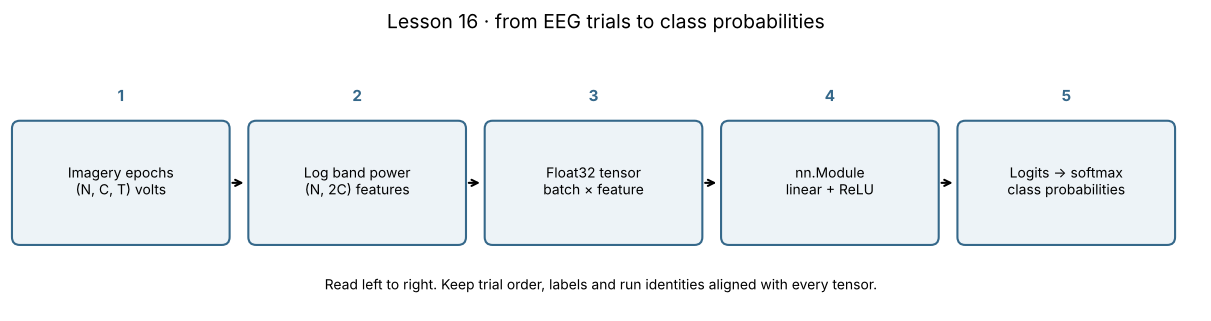

In [2]:
# Drawing code for the lesson map; no analysis data are transformed here.
from matplotlib.patches import FancyBboxPatch
map_steps=['Imagery epochs\n(N, C, T) volts', 'Log band power\n(N, 2C) features', 'Float32 tensor\nbatch × feature', 'nn.Module\nlinear + ReLU', 'Logits → softmax\nclass probabilities']
fig,map_ax=plt.subplots(figsize=(12,3.1),constrained_layout=True)
map_ax.set(xlim=(-.1,12),ylim=(-.3,2.4));map_ax.axis('off')
for map_i,map_label in enumerate(map_steps):
    map_x=map_i*2.4
    map_ax.add_patch(FancyBboxPatch((map_x,.45),2.05,1.1,
        boxstyle='round,pad=0.08',facecolor='#edf3f7',edgecolor='#35688a',linewidth=1.5))
    map_ax.text(map_x+1.025,1.02,map_label,ha='center',va='center',fontsize=10)
    map_ax.text(map_x+1.025,1.83,str(map_i+1),ha='center',weight='bold',color='#35688a')
    if map_i<4:map_ax.annotate('',xy=(map_x+2.3,1),xytext=(map_x+2.13,1),arrowprops=dict(arrowstyle='->',lw=1.5))
map_ax.text(5.9,-.08,'Read left to right. Keep trial order, labels and run identities aligned with every tensor.',ha='center',fontsize=10)
map_ax.set_title('Lesson 16 · from EEG trials to class probabilities',fontsize=14,pad=12)
plt.show()

**Read the map:** this lesson stops at step 5 with an *untrained* network. Its probabilities are close to 0.5 because the weights are random. Lesson 17 trains the weights. The map as text: Imagery epochs (N, C, T) → log band power (N, 2C) → float32 tensor → nn.Module → logits and softmax probabilities.

## Symbols and a calculation by hand

$x_i$: input feature; $w_i$: weight; $b$: bias; $f$: activation function; $z_k$: logit for class $k$; $p_k$: probability for class $k$.

### Derive the operation before calling the library

Take one trial with two features: log mu power at C3, $x_1=-0.4$, and at C4, $x_2=0.6$. With weights $w=(1.5,-1.0)$ and bias $b=0.2$, the weighted sum is $1.5(-0.4)+(-1.0)(0.6)+0.2=-1.0$. A ReLU activation $f(s)=\max(0,s)$ outputs $0$; a sigmoid $f(s)=1/(1+e^{-s})$ outputs $0.269$.

A layer with 3 neurons and these 2 inputs has a weight matrix of shape $(3,2)$ and 3 biases: $3\times2+3=9$ trainable parameters. A layer with $d_{in}$ inputs and $d_{out}$ outputs has $d_{out}(d_{in}+1)$ parameters.

### Your paper calculation

Repeat the weighted sum with $x_1=0.6$ and $x_2=-0.4$ (the hemispheres swapped). Which activation outputs change? Band power is measured in V²/Hz; after standardization the features have no unit, so the weights and the weighted sum have none either.

**My calculation:** _write your intermediate steps here before continuing._

### From an image classifier to an EEG classifier

The MNIST tutorial flattens a 28 × 28 image into 784 input values. Here one trial is first reduced to $2C=128$ features: log mu power and log beta power for each of 64 channels. A fully connected network ignores the spatial arrangement of the inputs; it treats feature 0 and feature 127 the same way. That is acceptable for band-power features, where the spatial information has already been summarized per channel, but it discards temporal structure. Lesson 17 uses convolutions to keep it.

### Tensors are arrays with gradients and devices

A tensor is an n-dimensional array, like a NumPy `ndarray`. A vector is a 1-D tensor, a feature matrix a 2-D tensor, and a batch of EEG epochs a 3-D tensor of shape (trials, channels, samples). PyTorch adds two things NumPy lacks: automatic differentiation (Lesson 17) and the ability to move a tensor to a GPU with `.to(device)`.

Most tensor methods come in two forms. `x.add(1)` returns a new tensor; `x.add_(1)`, with a trailing underscore, modifies `x` in place. `torch.from_numpy(a)` shares memory with the array `a`: an in-place change to one changes the other. `torch.tensor(a)` copies. EEG arrays from MNE are float64; PyTorch layers default to float32, so convert explicitly.

### Logits, softmax and an untrained network

The last layer outputs one unbounded score per class, the logit. Softmax maps logits to probabilities that sum to one. With random initial weights, logits for the two classes are similar, so the predicted probabilities are near 0.5. This is the expected starting point, not a bug.

## Visual intuition · Activation functions shape a neuron's output

**Independent exercise:** For an input of $-1$, which activation returns exactly zero? Which returns a value between 0 and 1?

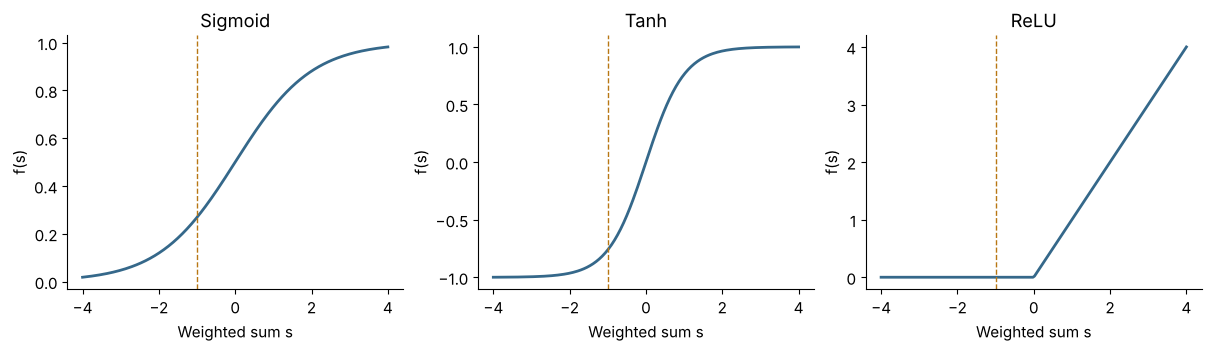

In [3]:
vis_s=np.linspace(-4,4,200)
fig,axes=plt.subplots(1,3,figsize=(12,3.4),constrained_layout=True)
for vis_ax,(vis_name,vis_f) in zip(axes,[('Sigmoid',1/(1+np.exp(-vis_s))),('Tanh',np.tanh(vis_s)),('ReLU',np.maximum(0,vis_s))]):
    vis_ax.plot(vis_s,vis_f,color='#35688a',lw=2)
    vis_ax.axvline(-1,color='#b87714',ls='--',lw=1)
    vis_ax.set(title=vis_name,xlabel='Weighted sum s',ylabel='f(s)')
plt.show()

### Worked interpretation

ReLU returns exactly zero for any negative input; sigmoid returns 0.269 at $s=-1$ and always lies between 0 and 1; tanh is centred on zero. Without a nonlinear activation, stacked linear layers collapse to a single linear map, so the network could not represent anything a linear classifier cannot.

## Guided practice 1 · one neuron on two band-power features

Compute the neuron from the hand calculation with NumPy.

**Independent exercise on paper:** predict the ReLU and sigmoid outputs before running.

**My prediction:** _write here._

**Hint:** the weighted sum is a dot product plus the bias.

### Worked solution · read one statement at a time

In [4]:
demo_x=np.array([-0.4,0.6])
demo_w=np.array([1.5,-1.0])
demo_b=0.2
demo_s=demo_x@demo_w+demo_b
print('Weighted sum:',demo_s,'| ReLU:',max(0.0,demo_s),'| sigmoid:',round(1/(1+np.exp(-demo_s)),3))

Weighted sum: -1.0000000000000002 | ReLU: 0.0 | sigmoid: 0.269


### Why this result makes sense

The neuron weights C3 positively and C4 negatively, so it responds to an asymmetry between hemispheres, the kind of contrast that distinguishes left- from right-hand imagery.

**Check your understanding:** swap the two inputs, predict the new sign, and rerun.

## Guided practice 2 · a layer is a matrix product

Apply three neurons to a batch of four trials in one matrix product and check the output shape.

**Independent exercise on paper:** with inputs of shape (4, 2) and weights of shape (3, 2), what shape does `X @ W.T + b` have?

**My prediction:** _write here._

**Hint:** the inner dimensions must match; the outer dimensions remain.

### Worked solution · read one statement at a time

In [5]:
demo_X=np.array([[-0.4,0.6],[0.6,-0.4],[0.1,0.1],[-1.0,1.0]])
demo_W=np.array([[1.5,-1.0],[-1.5,1.0],[0.5,0.5]])
demo_bias=np.array([0.2,0.2,0.0])
demo_H=np.maximum(0,demo_X@demo_W.T+demo_bias)
print('Hidden layer shape:',demo_H.shape)
print(demo_H)

Hidden layer shape: (4, 3)
[[0.   1.4  0.1 ]
 [1.5  0.   0.1 ]
 [0.25 0.15 0.1 ]
 [0.   2.7  0.  ]]


### Why this result makes sense

Each row is still one trial and each column is now one neuron. The trial axis is never mixed, which is why labels stay aligned with rows.

**Check your understanding:** add a fifth trial and predict the new output shape.

## Guided practice 3 · softmax turns logits into probabilities

Compute softmax for logits that are equal, slightly different and very different.

**Independent exercise on paper:** which logit pair gives probabilities closest to 0.5?

**My prediction:** _write here._

**Hint:** only the difference between the two logits matters.

### Worked solution · read one statement at a time

In [6]:
def demo_softmax(z):
    z=np.asarray(z,dtype=float)
    ez=np.exp(z-z.max())
    return ez/ez.sum()
for demo_z in [[0.0,0.0],[0.1,-0.1],[3.0,-3.0]]:
    print(demo_z,'→',demo_softmax(demo_z).round(3))

[0.0, 0.0] → [0.5 0.5]
[0.1, -0.1] → [0.55 0.45]
[3.0, -3.0] → [0.998 0.002]


### Why this result makes sense

Equal logits give 0.5/0.5; a small difference, as produced by small random weights, gives probabilities close to 0.5. Subtracting the maximum before exponentiating avoids overflow without changing the result.

**Check your understanding:** add 1000 to both logits and confirm the probabilities do not change.

## Guided practice 4 · count the parameters of a fully connected network

Count parameters for a network with 128 inputs, hidden layers of 64 and 32 units, and 2 outputs.

**Independent exercise on paper:** apply $d_{out}(d_{in}+1)$ to each layer and add.

**My prediction:** _write here._

**Hint:** there are three weight matrices.

### Worked solution · read one statement at a time

In [7]:
demo_sizes=[128,64,32,2]
demo_counts=[d_out*(d_in+1) for d_in,d_out in zip(demo_sizes[:-1],demo_sizes[1:])]
print('Per layer:',demo_counts,'| total:',sum(demo_counts))

Per layer: [8256, 2080, 66] | total: 10402


### Why this result makes sense

The network has 10,402 parameters, while the training run below has only about 75 trials (five participants × about 15 trials each). A model with far more parameters than trials can memorize its training data, which is why Lesson 17 needs a separate validation run.

**Check your understanding:** halve the first hidden layer and recount.

## Practice 1 · A fully connected layer with ReLU

Implement `dense_relu(X, W, b)` for a batch `X` of shape (N, d_in), weights `W` of shape (d_out, d_in) and biases `b` of shape (d_out,). Return ReLU of the layer output.

**Independent exercise:** complete the function below before reading its solution. The template deliberately returns None so that an unfinished attempt does not interrupt the rest of the lesson.

In [8]:
def dense_relu(X, W, b):
    # TODO: compute max(0, X W^T + b) for every trial.
    return None

### Hint

This is the same computation as Guided practice 2. `nn.Linear` stores its weights with shape (d_out, d_in), so transpose `W`.

### Worked solution

Compare this implementation with your attempt. The next cell checks the reference answer on a concrete numerical case.

In [9]:
def dense_relu(X, W, b):
    return np.maximum(0, X @ W.T + b)

In [10]:
answer=dense_relu(np.array([[-0.4,0.6]]),np.array([[1.5,-1.0],[-1.5,1.0]]),np.array([0.2,0.2]))
if answer is not None:
    assert answer.shape==(1,2) and np.allclose(answer,[[0.0,1.4]]); print('Layer check passed.')
else: print('Exercise pending: implement dense_relu.')

Layer check passed.


## Apply the ideas to the complete pipeline

The next stages use the real EEGBCI recordings. Read each stage's explanation before running its code.

### Method reference for the pipeline

Each run is filtered to 8–30 Hz, epoched from 0.5 to 3.5 s after the cue, and resampled to 80 Hz (enough for a signal with nothing above 30 Hz). Welch's method estimates power spectral density per trial and channel; averaging over 8–13 Hz and 13–30 Hz and taking $\log_{10}$ gives two features per channel. The resulting tensors keep one row per trial, in the same order as the labels and run identifiers.

## Load EEG trials
Subjects 1–5 are downloaded once (about 40 MB) and cached. Each run is processed separately so that filtering never crosses a run boundary.

### Step 1.1 · load, filter and epoch each run

**1.** Fix the subjects, runs and analysis window before looking at any result.

**2.** For every subject and run, load the EDF file, standardize channel names, set the montage and average reference, filter, and epoch the two imagery cues.

**3.** Record one subject ID and one run ID per retained trial.

In [11]:
from mne.datasets import eegbci
SUBJECTS = [1, 2, 3, 4, 5]
RUNS = [4, 8, 12]
parts, subject_ids, run_ids = [], [], []
for subject in SUBJECTS:
    for run in RUNS:
        # Retrieve one run; filtering is applied to this run alone.
        path = eegbci.load_data(subject, [run], path=DATA_ROOT, update_path=False)[0]
        raw_run = mne.io.read_raw_edf(path, preload=True, verbose=False)
        eegbci.standardize(raw_run)
        raw_run.set_montage('standard_1005')
        raw_run.set_eeg_reference('average', projection=False)
        raw_run.filter(8, 30, fir_design='firwin')
        # Halve the sampling rate (160 → 80 Hz); resample applies its own anti-alias filter.
        raw_run.resample(80)
        # T1 = left fist imagery, T2 = right fist imagery in runs 4, 8 and 12.
        events, _ = mne.events_from_annotations(raw_run, event_id={'T1': 1, 'T2': 2})
        ep = mne.Epochs(raw_run, events, {'left': 1, 'right': 2}, tmin=0.5, tmax=3.5,
                        baseline=None, preload=True, picks='eeg',
                        reject_by_annotation=True)
        parts.append(ep)
        subject_ids += [subject] * len(ep)
        run_ids += [run] * len(ep)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


... (5 outputs left out)

/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


/tmp/ipykernel_754/2466209037.py:11: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_run.set_montage('standard_1005')


### Step 1.2 · collect arrays and check alignment

**1.** Concatenate the epochs and expose the data in volts with shape (N, C, T).

**2.** Convert event codes 1/2 to class labels 0/1 in the same row order.

**3.** Check that labels, subject IDs and run IDs all have one entry per trial.

In [12]:
epochs = mne.concatenate_epochs(parts)
X = epochs.get_data(copy=True)
y = epochs.events[:, 2] - 1
subject_ids = np.asarray(subject_ids)
run_ids = np.asarray(run_ids)
sfreq = epochs.info['sfreq']
assert len(X) == len(y) == len(subject_ids) == len(run_ids)
print('Epochs (N, C, T):', X.shape, '| dtype:', X.dtype, '| sampling rate:', sfreq, 'Hz')
print(pd.crosstab(run_ids, y, rownames=['run'], colnames=['class 0 = left, 1 = right']))

/tmp/ipykernel_754/267033981.py:1: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = mne.concatenate_epochs(parts)


Epochs (N, C, T): (225, 64, 241) | dtype: float64 | sampling rate: 80.0 Hz
class 0 = left, 1 = right   0   1
run                              
4                          38  37
8                          37  38
12                         38  37


### Inspect and interpret

Each participant contributes about 15 trials per run, so each run has about 75 trials, roughly 37 per class. The array is float64 because MNE stores volts in double precision. Rows are trials; never shuffle `X` without shuffling `y`, `subject_ids` and `run_ids` the same way.

## PyTorch tensors with EEG
This section repeats the tensor basics of the MNIST tutorial with EEG arrays instead of random numbers.

### Step 2.1 · create tensors and do arithmetic

**1.** Create a small random tensor and a tensor of ones with the same size.

**2.** Add them and index rows and columns exactly as with NumPy.

In [13]:
demo_a = torch.rand(3, 2)
demo_ones = torch.ones(demo_a.size())
demo_sum = demo_a + demo_ones
print(demo_sum)
print('First row:', demo_sum[0], '| second column:', demo_sum[:, 1])

tensor([[1.7269, 1.6690],
        [1.5022, 1.3414],
        [1.0724, 1.9213]])
First row: tensor([1.7269, 1.6690]) | second column: tensor([1.6690, 1.3414, 1.9213])


### Step 2.2 · in-place operations end with an underscore

**1.** `add` returns a new tensor and leaves the original unchanged.

**2.** `add_` changes the tensor in place.

In [14]:
demo_new = demo_sum.add(1)
print('After add (original unchanged):', demo_sum[0])
demo_sum.add_(10)
print('After add_ (original changed):', demo_sum[0])

After add (original unchanged): tensor([1.7269, 1.6690])
After add_ (original changed): tensor([11.7269, 11.6690])


### Step 2.3 · NumPy to Torch and back

**1.** `torch.from_numpy` wraps the EEG array without copying it; both objects share memory.

**2.** An in-place multiplication of the tensor therefore also changes the NumPy array. Work on a copy so the analysis data stay unchanged.

In [15]:
X_copy = X[:2].copy()
shared = torch.from_numpy(X_copy)
print('Shared tensor dtype:', shared.dtype, '| shape:', tuple(shared.shape))
before = X_copy[0, 0, 0]
shared.mul_(2)
print('NumPy value before / after in-place tensor change:', before, X_copy[0, 0, 0])
print('Same memory:', np.shares_memory(X_copy, shared.numpy()))

Shared tensor dtype: torch.float64 | shape: (2, 64, 241)
NumPy value before / after in-place tensor change: 4.943029745366915e-06 9.88605949073383e-06
Same memory: True


### Inspect and interpret

The NumPy value doubled even though only the tensor was changed. This is useful for speed and dangerous for analysis: a later in-place operation could silently alter your recorded data. `torch.tensor(X, dtype=torch.float32)` copies and converts in one step.

### Step 2.4 · convert the epochs to a float32 tensor

**1.** Copy the epochs into a float32 tensor of shape (N, C, T).

**2.** Index a single trial, a single channel and a time slice; read the shape after each operation.

In [16]:
epochs_tensor = torch.tensor(X, dtype=torch.float32)
c3 = epochs.ch_names.index('C3')
print('All trials:', tuple(epochs_tensor.shape))
print('One trial (C, T):', tuple(epochs_tensor[0].shape))
print('C3 for every trial (N, T):', tuple(epochs_tensor[:, c3, :].shape))
print('First second of trial 0 at C3:', tuple(epochs_tensor[0, c3, :int(sfreq)].shape))

All trials: (225, 64, 241)
One trial (C, T): (64, 241)
C3 for every trial (N, T): (225, 241)
First second of trial 0 at C3: (80,)


### Step 2.5 · reshape without losing the trial axis

**1.** `reshape(N, -1)` flattens channels and time into one feature axis, like flattening a 28 × 28 image to 784 values.

**2.** `permute` reorders axes, for example to (N, T, C).

**3.** The MNIST tutorial used `resize_`, which can silently drop or invent values when the size changes; prefer `reshape` or `view`, which refuse an impossible shape.

In [17]:
n_trials = epochs_tensor.shape[0]
flat = epochs_tensor.reshape(n_trials, -1)
print('Flattened (N, C·T):', tuple(flat.shape))
print('Permuted (N, T, C):', tuple(epochs_tensor.permute(0, 2, 1).shape))
try:
    epochs_tensor.reshape(n_trials, 1000)
except RuntimeError as error:
    print('reshape refuses an impossible shape:', str(error)[:60], '...')
assert torch.equal(flat[0, :epochs_tensor.shape[2]], epochs_tensor[0, 0])

Flattened (N, C·T): (225, 15424)
Permuted (N, T, C): (225, 241, 64)
reshape refuses an impossible shape: shape '[225, 1000]' is invalid for input of size 3470400 ...


### Inspect and interpret

Flattening a trial gives 64 × 241 ≈ 15,000 values, far more than the number of trials. That is why this lesson feeds the network compact band-power features instead of raw samples.

## Practice 2 · Find a channel's values in the flattened tensor

**Independent exercise:** In `flat`, which columns hold channel C4 of each trial? Extract them and check they equal `epochs_tensor[:, c4, :]`.

**My reasoning / hand calculation:** _write here._

In [18]:
# Your attempt goes here. Work on copies and preserve the evaluation split.

### Hint

Row-major flattening places channel $c$ in columns $cT$ to $(c+1)T-1$.

### Worked solution

Run the following calculation after attempting your own version.

In [19]:
c4 = epochs.ch_names.index('C4')
n_times = epochs_tensor.shape[2]
c4_columns = flat[:, c4 * n_times:(c4 + 1) * n_times]
print('C4 columns:', c4 * n_times, 'to', (c4 + 1) * n_times - 1)
assert torch.equal(c4_columns, epochs_tensor[:, c4, :]); print('C4 slice check passed.')

C4 columns: 2892 to 3132
C4 slice check passed.


### Interpret and check

Flattening keeps channel blocks contiguous. A fully connected layer on `flat` would see these blocks only as positions; it would not know they are neighbouring samples in time.

## Band-power features as a tensor
Each trial becomes 128 numbers: log mu and log beta power for each of the 64 channels.

### Step 3.1 · estimate power spectra and average within bands

**1.** Welch's method gives a power spectral density per trial and channel.

**2.** Average within the mu and beta bands, take log10 and place the two bands side by side.

In [20]:
freqs, psd = signal.welch(X, fs=sfreq, nperseg=int(sfreq), axis=-1)
mu_band = (freqs >= 8) & (freqs <= 13)
beta_band = (freqs > 13) & (freqs <= 30)
features = np.concatenate([np.log10(psd[:, :, mu_band].mean(-1)),
                           np.log10(psd[:, :, beta_band].mean(-1))], axis=1)
print('PSD (N, C, F):', psd.shape, '| features (N, 2C):', features.shape)

PSD (N, C, F): (225, 64, 41) | features (N, 2C): (225, 128)


### Step 3.2 · standardize with training-run statistics and convert

**1.** Run 4 is the training run. Feature means and standard deviations come from it alone.

**2.** The same scaling is applied to every trial, and the result is converted to float32 tensors with integer labels.

In [21]:
train = run_ids == 4
feat_mean = features[train].mean(axis=0)
feat_std = features[train].std(axis=0)
features_t = torch.tensor((features - feat_mean) / feat_std, dtype=torch.float32)
labels_t = torch.tensor(y, dtype=torch.long)
print('Feature tensor:', tuple(features_t.shape), features_t.dtype, '| labels:', tuple(labels_t.shape), labels_t.dtype)

Feature tensor: (225, 128) torch.float32 | labels: (225,) torch.int64


### Inspect and interpret

Labels are `long` (64-bit integers) because PyTorch's classification loss expects class indices. Features use training-run scaling only; Lesson 17 explains why validation and test runs must not influence it.

## Practice 3 · Check the scaling

**Independent exercise:** Show that training-run features have mean ≈ 0 and standard deviation ≈ 1, and report the same statistics for run 12.

**My reasoning / hand calculation:** _write here._

In [22]:
# Your attempt goes here. Work on copies and preserve the evaluation split.

### Hint

Index `features_t` with a boolean tensor built from `run_ids`.

### Worked solution

Run the following calculation after attempting your own version.

In [23]:
for run in RUNS:
    rows = torch.tensor(run_ids == run)
    print(f'Run {run}: mean {features_t[rows].mean():.3f}, std {features_t[rows].std():.3f}')

Run 4: mean -0.000, std 1.000
Run 8: mean -0.007, std 0.987
Run 12: mean -0.075, std 1.066


### Interpret and check

Run 4 is centred by construction; runs 8 and 12 need not be. A shift between runs is real information about non-stationarity, not an error to be fixed with test statistics.

## Build a network with `nn.Module`
A network is a Python class that inherits from `nn.Module`. Layers are created in `__init__`; `forward` says how data flow through them.

### Step 4.1 · define the network

**1.** Three fully connected layers map 128 features → 64 → 32 → 2 logits.

**2.** ReLU follows each hidden layer; the output layer returns logits without an activation.

**3.** `predict` applies softmax along the class dimension (`dim=1`) to give probabilities.

In [24]:
class Network(nn.Module):
    def __init__(self, n_features, n_hidden1=64, n_hidden2=32, n_classes=2):
        super().__init__()
        self.fc1 = nn.Linear(n_features, n_hidden1)
        self.fc2 = nn.Linear(n_hidden1, n_hidden2)
        self.fc3 = nn.Linear(n_hidden2, n_classes)

    def forward(self, x):
        """Return logits, one row per trial and one column per class."""
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

    def predict(self, x):
        """Return class probabilities from the logits."""
        return F.softmax(self.forward(x), dim=1)

net = Network(n_features=features_t.shape[1])
print(net)
print('Trainable parameters:', sum(p.numel() for p in net.parameters()))

Network(
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=2, bias=True)
)
Trainable parameters: 10402


### Inspect and interpret

The parameter count matches Guided practice 4. Printing the module lists its layers but not the order of operations in `forward`; read the method to see it.

### Step 4.2 · inspect and initialize weights and biases

**1.** Each `nn.Linear` holds a `weight` of shape (out, in) and a `bias` of shape (out,).

**2.** Custom initialization modifies these tensors in place under `torch.no_grad()`, so the change is not recorded for differentiation.

In [25]:
print('fc1.weight:', tuple(net.fc1.weight.shape), '| fc1.bias:', tuple(net.fc1.bias.shape))
print('Default initial weights, first neuron:', net.fc1.weight[0, :5].detach())
with torch.no_grad():
    net.fc1.bias.fill_(0)
    net.fc1.weight.normal_(std=0.01)
print('After custom initialization:', net.fc1.weight[0, :5].detach(), '| bias sum:', net.fc1.bias.sum().item())

fc1.weight: (64, 128) | fc1.bias: (64,)
Default initial weights, first neuron: tensor([-0.0423, -0.0241,  0.0558,  0.0429, -0.0278])
After custom initialization: tensor([ 0.0060,  0.0046, -0.0008,  0.0030, -0.0154]) | bias sum: 0.0


### Inspect and interpret

The original MNIST notebook used `.data` to bypass gradient tracking; `torch.no_grad()` is the current, safer form. Very small initial weights (std 0.01) make the hidden activations, and so the logits, small. Remember this when reading the next output.

## Practice 4 · Count parameters per layer

**Independent exercise:** Use `net.named_parameters()` to print each parameter's name, shape and number of values, and check the total against Guided practice 4.

**My reasoning / hand calculation:** _write here._

In [26]:
# Your attempt goes here. Work on copies and preserve the evaluation split.

### Hint

`p.numel()` returns the number of values in a tensor.

### Worked solution

Run the following calculation after attempting your own version.

In [27]:
layer_total = 0
for name, p in net.named_parameters():
    print(f'{name:12s} {str(tuple(p.shape)):10s} {p.numel():6d}')
    layer_total += p.numel()
assert layer_total == 10402; print('Total:', layer_total)

fc1.weight   (64, 128)    8192
fc1.bias     (64,)          64
fc2.weight   (32, 64)     2048
fc2.bias     (32,)          32
fc3.weight   (2, 32)        64
fc3.bias     (2,)            2
Total: 10402


### Interpret and check

Most parameters sit in `fc1.weight`, because the first layer connects every input feature to every hidden unit.

## Forward pass with an untrained network
Pass real trials through the network. With random weights the output should not depend on the class.

### Step 5.1 · pass one batch through the network

**1.** Take the first 32 training trials as a batch of shape (32, 128).

**2.** Compute logits and probabilities without building a gradient graph.

In [28]:
batch = features_t[torch.tensor(train)][:32]
batch_labels = labels_t[torch.tensor(train)][:32]
with torch.no_grad():
    logits = net(batch)
    probs = net.predict(batch)
print('Logits shape:', tuple(logits.shape), '| first rows:\n', logits[:3])
print('Probabilities, first rows:\n', probs[:3])
print('Each row sums to:', probs.sum(dim=1)[:3])

Logits shape: (32, 2) | first rows:
 tensor([[0.0633, 0.1000],
        [0.0763, 0.1049],
        [0.0683, 0.0985]])
Probabilities, first rows:
 tensor([[0.4908, 0.5092],
        [0.4928, 0.5072],
        [0.4925, 0.5075]])
Each row sums to: tensor([1., 1., 1.])


### Step 5.2 · show one trial and the network's prediction

**1.** Plot the C3 and C4 signals of one trial.

**2.** Show the predicted class probabilities next to the true label, like the MNIST tutorial's `view_classify` helper.

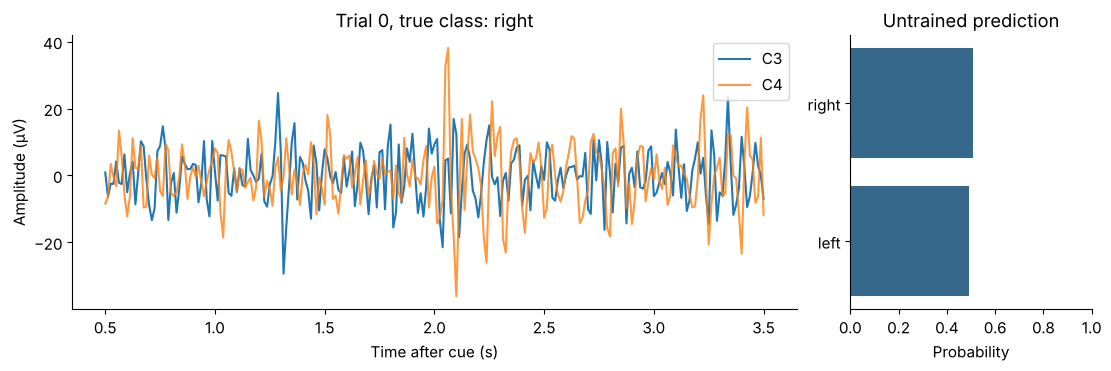

In [29]:
trial = int(np.flatnonzero(train)[0])
times = epochs.times
fig, (ax_sig, ax_prob) = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True,
                                      gridspec_kw={'width_ratios': [3, 1]})
ax_sig.plot(times, X[trial, c3] * 1e6, label='C3')
ax_sig.plot(times, X[trial, c4] * 1e6, label='C4', alpha=0.8)
ax_sig.set(xlabel='Time after cue (s)', ylabel='Amplitude (µV)',
           title=f'Trial {trial}, true class: {["left", "right"][y[trial]]}')
ax_sig.legend(loc='upper right')
ax_prob.barh(['left', 'right'], probs[0].numpy(), color='#35688a')
ax_prob.set(xlim=(0, 1), xlabel='Probability', title='Untrained prediction')
plt.show()

### Inspect and interpret

The probabilities are close to 0.5 for both classes. The network has not seen any labels, so it cannot know whether this trial is left or right. Training (Lesson 17) changes the weights so that the probability of the correct class rises.

## Practice 5 · Untrained accuracy is chance

**Independent exercise:** Predict a class for every trial with the untrained network (`argmax` of the logits) and compute balanced accuracy. Repeat with two other random seeds.

**My reasoning / hand calculation:** _write here._

In [30]:
# Your attempt goes here. Work on copies and preserve the evaluation split.

### Hint

Re-create the network after `torch.manual_seed(seed)` so each seed gives new random weights.

### Worked solution

Run the following calculation after attempting your own version.

In [31]:
from sklearn.metrics import balanced_accuracy_score
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    untrained = Network(n_features=features_t.shape[1])
    with torch.no_grad():
        guess = untrained(features_t).argmax(dim=1).numpy()
    print(f'Seed {seed}: balanced accuracy {balanced_accuracy_score(y, guess):.3f}')
torch.manual_seed(SEED)

Seed 0: balanced accuracy 0.486
Seed 1: balanced accuracy 0.499
Seed 2: balanced accuracy 0.519


### Interpret and check

The values scatter around 0.5. Some seeds may happen to predict one class for nearly every trial, which gives exactly 0.5 balanced accuracy. A trained model has to beat this level by more than chance variation.

## Recorded-signal inspection with MNE-Python

The network sees log band power. The following view shows the measured spectra behind those features at C3 and C4, by class, for the training run.

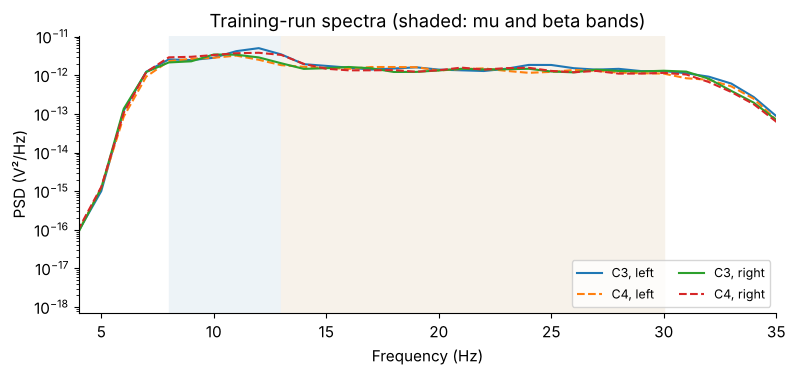

In [32]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for cls, name in enumerate(['left', 'right']):
    rows = train & (y == cls)
    for ch, ls in [(c3, '-'), (c4, '--')]:
        ax.semilogy(freqs, psd[rows, ch].mean(0), ls=ls, label=f'{epochs.ch_names[ch]}, {name}')
ax.axvspan(8, 13, color='#edf3f7'); ax.axvspan(13, 30, color='#f7f2ea')
ax.set(xlim=(4, 35), xlabel='Frequency (Hz)', ylabel='PSD (V²/Hz)', title='Training-run spectra (shaded: mu and beta bands)')
ax.legend(ncol=2, fontsize=9)
plt.show()

### Figure interpretation and independent exercise

Spectra are averaged over training trials from five participants. A class difference at C3 or C4 in the shaded bands is what the network could learn to use. In this pooled average the four curves nearly overlap: any class difference is small compared with the variation across frequencies, a first sign that decoding will be hard. The figure is descriptive: it does not show that the difference is significant or that it will transfer to run 12.

**Exercise.** Name the unit of the vertical axis, and say why averaging across participants could hide a lateralized ERD.

**Reference interpretation.** The unit is V²/Hz. Participants differ in their dominant frequency and in which hemisphere shows the clearest ERD; averaging can cancel opposite effects or be dominated by one participant with high power.

## Practice 6 · explain the complete method

Independently explain how a recorded EEG trial becomes a probability in this notebook. Include one place where trial order could be broken and one claim the untrained output does not support.

**My explanation:** _write here._

### Worked answer · compare your reasoning

Each run is filtered and epoched; Welch spectra are averaged into log mu and beta power per channel; training-run statistics standardize the features; a float32 tensor passes through three linear layers with ReLU; softmax turns logits into probabilities. Trial order could break if features were shuffled without labels and run IDs. Untrained probabilities say nothing about whether the features contain class information.

## If your result is different

If a layer raises a shape error, print `x.shape` before it and compare with `in_features`. If a loss later complains about dtype, check that features are float32 and labels are int64 (`long`). If a download fails, retry when PhysioNet is reachable; do not replace real data with simulated values.

## Can you now do this independently?

- Convert an MNE epochs array to a float32 tensor and explain the shared-memory risk of `from_numpy`.
- Reshape a batch without mixing trials, and find one channel inside a flattened trial.
- Write an `nn.Module` with `__init__`, `forward` and `predict`, and count its parameters.
- Explain why untrained probabilities are near 0.5.

If one item is unclear, return to the associated practice before Lesson 17.

## Next steps and sources
Lesson 17 trains this network with gradient descent, adds a convolutional network on raw epochs, and saves the trained model.

[PyTorch tensors tutorial](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) · [Building models with nn.Module](https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) · [MNE EEGBCI](https://mne.tools/stable/generated/mne.datasets.eegbci.load_data.html).

## References and further reading

1. [Gramfort et al. (2013), MEG and EEG data analysis with MNE-Python](https://doi.org/10.3389/fnins.2013.00267).
2. [PhysioNet EEG Motor Movement/Imagery Dataset](https://physionet.org/content/eegmmidb/1.0.0/).
3. [Paszke et al. (2019), PyTorch: an imperative style, high-performance deep learning library](https://arxiv.org/abs/1912.01703).
4. [Pfurtscheller and Lopes da Silva (1999). Event-related EEG/MEG synchronization and desynchronization](https://doi.org/10.1016/S1388-2457(99)00141-8).
5. [Schirrmeister et al. (2017). Deep learning with convolutional neural networks for EEG decoding and visualization](https://doi.org/10.1002/hbm.23730).

Numerical outcomes in this notebook refer only to the selected participants, runs and processing; they are not population performance estimates.